# WBCBench 2026 — Aşama 2: Dataset + DataLoader

Bu notebook model eğitmez. `phase2_train`, `phase2_eval` ve `phase2_test` klasörlerini kontrol eder, sınıf dağılımlarını gösterir ve güvenli bir DataLoader testi yapar.

**Eşleme:** `phase2_train` = train, `phase2_eval` = validation, `phase2_test` = final test.


In [1]:
from pathlib import Path
from collections import Counter
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu126
CUDA: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
DATA_DIR = Path("wbc_project/data/processed")
TRAIN_DIR = DATA_DIR / "phase2_train"
VAL_DIR = DATA_DIR / "phase2_eval"
TEST_DIR = DATA_DIR / "phase2_test"

for name, path in [("TRAIN", TRAIN_DIR), ("VAL", VAL_DIR), ("TEST", TEST_DIR)]:
    print(f"{name}: {path.resolve()} | exists={path.exists()}")

assert TRAIN_DIR.exists(), f"Bulunamadı: {TRAIN_DIR.resolve()}"
assert VAL_DIR.exists(), f"Bulunamadı: {VAL_DIR.resolve()}"
assert TEST_DIR.exists(), f"Bulunamadı: {TEST_DIR.resolve()}"
print("\n✓ Üç klasör de bulundu.")


TRAIN: C:\Users\sarah\Desktop\scı5\wbc_project\data\processed\phase2_train | exists=True
VAL: C:\Users\sarah\Desktop\scı5\wbc_project\data\processed\phase2_eval | exists=True
TEST: C:\Users\sarah\Desktop\scı5\wbc_project\data\processed\phase2_test | exists=True

✓ Üç klasör de bulundu.


In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=transform)
val_ds = datasets.ImageFolder(VAL_DIR, transform=transform)
test_ds = datasets.ImageFolder(TEST_DIR, transform=transform)

print("Sınıflar:", train_ds.classes)
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

assert train_ds.classes == val_ds.classes == test_ds.classes, "Split sınıfları aynı değil."
print("✓ Sınıflar uyumlu.")


Sınıflar: ['BA', 'BL', 'BNE', 'EO', 'LY', 'MMY', 'MO', 'MY', 'PC', 'PLY', 'PMY', 'SNE', 'VLY']
Train: 49794
Validation: 10700
Test: 32934
✓ Sınıflar uyumlu.


In [4]:
def distribution(ds, title):
    counts = Counter(ds.targets)
    print(f"\n--- {title} ---")
    for i, name in enumerate(ds.classes):
        print(f"{name:25s}: {counts[i]}")
    print(f"{'TOPLAM':25s}: {len(ds)}")

distribution(train_ds, "TRAIN")
distribution(val_ds, "VALIDATION")
distribution(test_ds, "TEST")



--- TRAIN ---
BA                       : 840
BL                       : 3398
BNE                      : 680
EO                       : 1596
LY                       : 13772
MMY                      : 670
MO                       : 4908
MY                       : 810
PC                       : 112
PLY                      : 22
PMY                      : 152
SNE                      : 22270
VLY                      : 564
TOPLAM                   : 49794

--- VALIDATION ---
BA                       : 120
BL                       : 824
BNE                      : 142
EO                       : 338
LY                       : 3142
MMY                      : 94
MO                       : 932
MY                       : 150
PC                       : 64
PLY                      : 2
PMY                      : 68
SNE                      : 4612
VLY                      : 212
TOPLAM                   : 10700

--- TEST ---
BA                       : 606
BL                       : 1770
BNE          

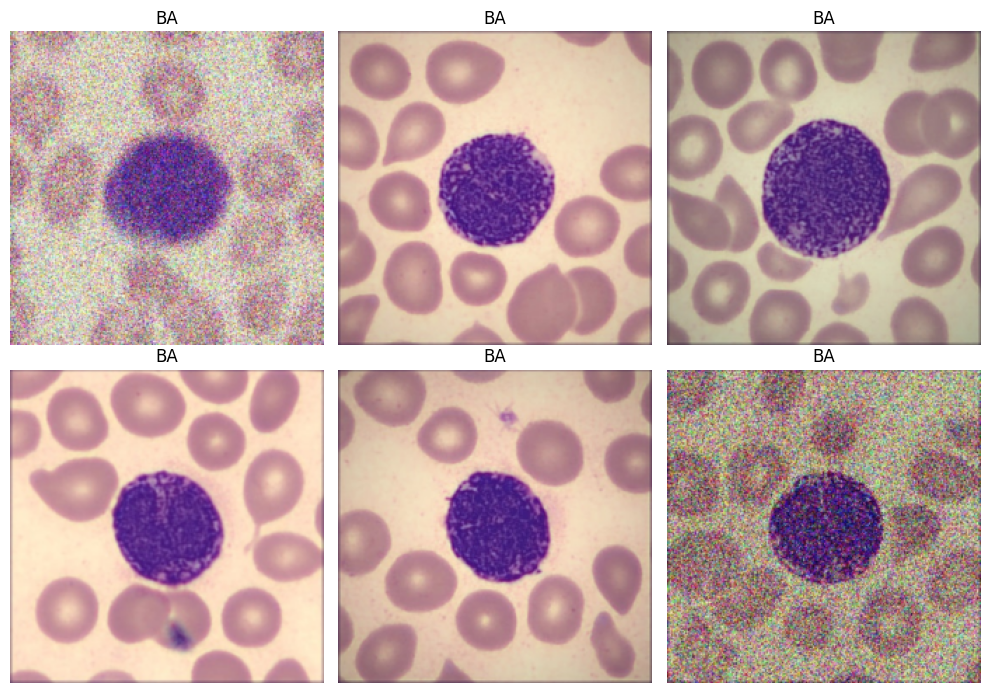

In [5]:
n = min(6, len(train_ds))
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i, ax in enumerate(axes.flatten()):
    if i < n:
        image, label = train_ds[i]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(train_ds.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()


## DataLoader testi

Windows + Jupyter ortamında takılma riskini azaltmak için ilk denemede `num_workers=0` kullanıyoruz. Batch size da yalnızca 8.


In [6]:
BATCH_SIZE = 8

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=torch.cuda.is_available())

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 6225
Val batches: 1338
Test batches: 4117


In [7]:
# Yalnızca bir batch okuyoruz.
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("dtype:", images.dtype)
print("Pixel min/max:", images.min().item(), images.max().item())

assert images.ndim == 4 and images.shape[1:] == (3, 224, 224)
print("\n✓ DataLoader başarıyla çalışıyor.")


Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
dtype: torch.float32
Pixel min/max: 0.054901961237192154 1.0

✓ DataLoader başarıyla çalışıyor.


In [8]:
print("=" * 50)
print("WBCBench AŞAMA 2 SONUCU")
print("=" * 50)
print("Sınıf sayısı:", len(train_ds.classes))
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("Batch size:", BATCH_SIZE)
print("Batch shape:", tuple(images.shape))
print("=" * 50)
print("✓ Veri hattı hazır.")
print("Sonraki aşama: ConvNeXt-Tiny kısa eğitim testi.")


WBCBench AŞAMA 2 SONUCU
Sınıf sayısı: 13
Train: 49794
Validation: 10700
Test: 32934
Batch size: 8
Batch shape: (8, 3, 224, 224)
✓ Veri hattı hazır.
Sonraki aşama: ConvNeXt-Tiny kısa eğitim testi.
